# 01 — Data Cleaning

**Project:** Learning the Path of the Storm — 24-hour tropical cyclone track forecasting
**Author:** Yatharth Vardan · AAI-590 Capstone, University of San Diego

**Rubric section:** Data Cleaning

This notebook turns the raw IBTrACS v04r01 best-track archive into a clean, regularly spaced table of
storm positions and intensities that the later notebooks (EDA, baselines, neural networks) all read from.
Every cleaning step prints how many rows it removed and why, and the counts are saved to a cleaning log.

| | |
|---|---|
| **Input** | `data/raw/ibtracs.since1980.list.v04r01.csv` (IBTrACS v04r01, NOAA NCEI; Gahtan et al., 2024) |
| **Cross-check** | `data/raw/hurdat2-1851-2024-040425.txt` (HURDAT2, NOAA NHC; Landsea & Franklin, 2013) |
| **Output** | `data/processed/tracks_clean.csv.gz`, `data/processed/cleaning_log.csv`, `reports/figures/fig01_cleaning_funnel.png` |

Run `python scripts/download_data.py` first if `data/raw/` is empty.

In [1]:
# Imports and paths
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from stormtrack.data_io import load_ibtracs, load_hurdat2, PROCESSED   # project helpers
from stormtrack.geo import haversine_km, bearing_deg, wrap_lon

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

## 1. Load the raw data

IBTrACS merges the best-track records of every official forecast agency into one file. Each row is one
storm position (a "fix") at one time. The file keeps several versions of wind and pressure (one per agency),
so only the columns this project needs are loaded.

In [2]:
raw = load_ibtracs()
print(f"Raw rows: {len(raw):,}   storms: {raw['SID'].nunique():,}   seasons: {raw['SEASON'].min()}-{raw['SEASON'].max()}")
raw.head()

Raw rows: 312,480   storms: 5,019   seasons: 1980-2027


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG,USA_AGENCY,USA_ATCF_ID,USA_WIND,USA_PRES,USA_SSHS,STORM_SPEED,STORM_DIR
0,1980001S13173,1980,1,SP,MM,PENI,1980-01-01 00:00:00,TS,-12.5,172.5,NaN,NaN,NaN,main,647,647.0,O_________OO_O_,jtwc_sh,SH051980,25.0,NaN,-1,6.0,350.0
1,1980001S13173,1980,1,SP,MM,PENI,1980-01-01 03:00:00,TS,-12.2,172.4,NaN,NaN,NaN,main,653,653.0,P_________PP_P_,NaN,SH051980,25.0,NaN,-1,6.0,350.0
2,1980001S13173,1980,1,SP,MM,PENI,1980-01-01 06:00:00,TS,-11.9,172.4,NaN,NaN,NaN,main,670,670.0,O_________OP_O_,jtwc_sh,SH051980,25.0,NaN,-1,5.0,360.0
3,1980001S13173,1980,1,SP,MM,PENI,1980-01-01 09:00:00,TS,-11.7,172.4,NaN,NaN,NaN,main,682,682.0,P_________PP_P_,NaN,SH051980,25.0,NaN,-1,4.0,10.0
4,1980001S13173,1980,1,SP,MM,PENI,1980-01-01 12:00:00,TS,-11.5,172.5,NaN,NaN,NaN,main,703,703.0,O_________OO_O_,jtwc_sh,SH051980,25.0,NaN,-1,4.0,20.0


In [3]:
# A cleaning log: one entry per step, recording rows and storms that remain.
log = []
def record(step, df, note):
    log.append({"step": step, "rows": len(df), "storms": df["SID"].nunique(), "note": note})
    print(f"{step:<38} rows={len(df):>8,}  storms={df['SID'].nunique():>6,}  | {note}")

record("0. Raw IBTrACS (since 1980)", raw, "as downloaded")

0. Raw IBTrACS (since 1980)            rows= 312,480  storms= 5,019  | as downloaded


## 2. Keep only final, main best tracks

`TRACK_TYPE` separates the main track of each storm from short "spur" tracks (branches created when
agencies disagree about a merge or split) and from **provisional** tracks for recent seasons that have not
yet been through post-season reanalysis. Provisional records (2025–2026) are operational estimates and would
be the *live* data source in production, but they are not final best tracks, so the model is trained and
tested only on finalized seasons up to 2024.

In [4]:
print(raw["TRACK_TYPE"].value_counts().to_string())
print()
print("Seasons with provisional tracks:", sorted(raw.loc[raw["TRACK_TYPE"].str.contains("PROVISIONAL"), "SEASON"].unique()))

df = raw[(raw["TRACK_TYPE"] == "main") & (raw["SEASON"] <= 2024)].copy()
record("1. Main, finalized tracks (<=2024)", df, "dropped spur + provisional tracks")

TRACK_TYPE
main                   300439
US-PROVISIONAL           6353
PROVISIONAL              4519
spur-merge                680
spur-other                317
spur-split                147
US-PROVISIONAL_spur        25

Seasons with provisional tracks: [np.int64(2025), np.int64(2026), np.int64(2027)]
1. Main, finalized tracks (<=2024)     rows= 298,196  storms= 4,740  | dropped spur + provisional tracks


## 3. Remove duplicate fixes

A storm should never have two rows at the same timestamp.

In [5]:
dups = df.duplicated(subset=["SID", "ISO_TIME"], keep="first")
print("Duplicate (SID, ISO_TIME) rows:", int(dups.sum()))
df = df[~dups]
record("2. Drop duplicate timestamps", df, f"{int(dups.sum())} duplicates removed")

Duplicate (SID, ISO_TIME) rows: 0
2. Drop duplicate timestamps           rows= 298,196  storms= 4,740  | 0 duplicates removed


## 4. Keep the regular 6-hourly synoptic times

Agencies record official fixes at 00, 06, 12 and 18 UTC. IBTrACS adds 3-hourly rows that are
**interpolated** (the `IFLAG` column marks them with `P`), plus occasional off-hour rows at landfall or peak
intensity. Interpolated rows are not real observations, and off-hour rows would make the time step
irregular, so only the four synoptic times are kept. A fixed 6-hour step is what the sequence models need.

In [6]:
hour = df["ISO_TIME"].dt.hour
on_synoptic = df["ISO_TIME"].dt.minute.eq(0) & hour.isin([0, 6, 12, 18])
print("Share of rows at 00/06/12/18 UTC:", round(on_synoptic.mean(), 3))
print("IFLAG first letter on removed rows:", df.loc[~on_synoptic, "IFLAG"].str[0].value_counts().to_dict())
df = df[on_synoptic].copy()
record("3. Synoptic times only", df, "dropped interpolated 3-hourly and off-hour rows")

Share of rows at 00/06/12/18 UTC: 0.502
IFLAG first letter on removed rows: {'P': 124927, '_': 22682, 'O': 487, 'V': 430}
3. Synoptic times only                 rows= 149,670  storms= 4,736  | dropped interpolated 3-hourly and off-hour rows


## 5. Keep tropical and subtropical stages only

`NATURE` describes the storm type at each fix: `TS` tropical, `SS` subtropical, `ET` extratropical,
`DS` disturbance, `MX` agencies disagree, `NR` not reported. Official track forecasts (and the NHC's own
verification) cover the tropical and subtropical stages, so only `TS` and `SS` fixes are kept. Removing the
other stages can leave gaps inside a storm; those are handled in Step 8 by splitting the track into
continuous segments rather than joining across the gap.

In [7]:
print(df["NATURE"].value_counts().to_string())
df = df[df["NATURE"].isin(["TS", "SS"])].copy()
record("4. Tropical / subtropical stages", df, "dropped ET, DS, MX, NR fixes")

NATURE
TS    113181
DS     11279
NR      8648
ET      7917
MX      7584
SS      1061


4. Tropical / subtropical stages       rows= 114,242  storms= 4,616  | dropped ET, DS, MX, NR fixes


## 6. Check coordinates

`LAT`/`LON` are the WMO-merged positions and are always present. Longitudes are wrapped to [-180, 180) so that
every basin uses the same convention.

In [8]:
print("Missing LAT/LON:", int(df[["LAT", "LON"]].isna().any(axis=1).sum()))
df["LON"] = wrap_lon(df["LON"])
print(df[["LAT", "LON"]].describe().round(2).T)
bad = ~df["LAT"].between(-70, 70)
print("Fixes outside +/-70 deg latitude:", int(bad.sum()))
df = df[~bad]
record("5. Coordinate checks", df, "wrapped longitudes; no invalid positions")

Missing LAT/LON: 0
        count   mean     std    min   25%   50%    75%    max
LAT  114242.0   7.87   18.11  -50.0 -12.3  14.3   20.5   51.9
LON  114242.0  41.76  109.05 -180.0 -72.3  87.2  130.6  179.9
Fixes outside +/-70 deg latitude: 0
5. Coordinate checks                   rows= 114,242  storms= 4,616  | wrapped longitudes; no invalid positions


## 7. Build one wind and one pressure column

Each agency reports intensity differently. The U.S. agencies (NHC, CPHC, JTWC) report **1-minute** sustained
winds in `USA_WIND`, which covers most fixes. Other agencies report **10-minute** winds in `WMO_WIND`. To keep a
single consistent unit, `USA_WIND` is used first and gaps are filled from `WMO_WIND / 0.88`, the standard
conversion from 10-minute to 1-minute winds (Harper et al., 2010). Pressure uses `USA_PRES`, then `WMO_PRES`.
Short gaps (up to 12 hours) inside a storm are then filled by linear interpolation in time; anything longer is
left missing and handled in Step 8.

In [9]:
miss_before = df[["USA_WIND", "WMO_WIND", "USA_PRES", "WMO_PRES"]].isna().mean().round(3)
print("Missing share before:\n", miss_before.to_string(), "\n")

df["wind_src"] = np.where(df["USA_WIND"].notna(), "usa_1min",
                  np.where(df["WMO_WIND"].notna(), "wmo_10min_converted", "missing"))
df["wind_kt"] = df["USA_WIND"].fillna(df["WMO_WIND"] / 0.88).round()
df["pres_mb"] = df["USA_PRES"].fillna(df["WMO_PRES"])
print(df["wind_src"].value_counts().to_string(), "\n")

df = df.sort_values(["SID", "ISO_TIME"]).reset_index(drop=True)

def fill_short_gaps(g, col, limit=2):
    # interpolate by time inside one storm, at most `limit` consecutive 6-h steps
    s = g.set_index("ISO_TIME")[col]
    return s.interpolate(method="time", limit=limit, limit_area="inside").to_numpy()

for col in ["wind_kt", "pres_mb"]:
    df[col] = np.concatenate([fill_short_gaps(g, col) for _, g in df.groupby("SID", sort=False)])

print("Missing share after:\n", df[["wind_kt", "pres_mb"]].isna().mean().round(3).to_string())

Missing share before:
 USA_WIND    0.095
WMO_WIND    0.199
USA_PRES    0.464
WMO_PRES    0.184 

wind_src
usa_1min               103417
wmo_10min_converted      6052
missing                  4773 



Missing share after:
 wind_kt    0.039
pres_mb    0.143


In [10]:
# Wind is a model input, so fixes still missing wind are removed (they become gaps).
no_wind = df["wind_kt"].isna()
df = df[~no_wind].copy()
record("6. Unified wind / pressure", df, f"{int(no_wind.sum())} fixes with no wind from any agency removed")

6. Unified wind / pressure             rows= 109,843  storms= 4,518  | 4399 fixes with no wind from any agency removed


## 8. Split each storm into continuous 6-hour segments

After the filters above, some storms have holes (for example, a storm that becomes extratropical and then
tropical again). A sequence model must never treat two fixes 30 hours apart as consecutive, so each storm is
split into **segments** wherever the time step is not exactly 6 hours.

The forecasting setup planned for the models uses the last 4 fixes (18 hours of history) to predict the
position 24 hours (4 steps) later, so a segment needs at least **8 fixes (42 hours)** to provide even one
training example. Shorter segments are dropped.

In [11]:
df = df.sort_values(["SID", "ISO_TIME"]).reset_index(drop=True)
step_h = df.groupby("SID")["ISO_TIME"].diff().dt.total_seconds() / 3600
new_seg = step_h.ne(6.0)                      # first fix of a storm or any gap starts a new segment
df["seg_no"] = new_seg.groupby(df["SID"]).cumsum().astype(int)
df["SEG_ID"] = df["SID"] + "_" + df["seg_no"].astype(str)

seg_len = df.groupby("SEG_ID")["ISO_TIME"].transform("size")
print("Segments:", df["SEG_ID"].nunique(), " | storms with more than one segment:",
      int((df.groupby("SID")["seg_no"].max() > 1).sum()))
print("Segment length (fixes):", seg_len.groupby(df["SEG_ID"]).first().describe().round(1).to_dict())

MIN_FIXES = 8
df = df[seg_len >= MIN_FIXES].copy()
record("7. Continuous segments >= 8 fixes", df, "split at gaps; dropped segments shorter than 42 h")

Segments: 5330  | storms with more than one segment: 622
Segment length (fixes): {'count': 5330.0, 'mean': 20.6, 'std': 15.1, 'min': 1.0, '25%': 9.0, '50%': 18.0, '75%': 29.0, 'max': 119.0}
7. Continuous segments >= 8 fixes      rows= 105,747  storms= 4,021  | split at gaps; dropped segments shorter than 42 h


## 9. Motion features and physically implausible jumps

For each fix, the 6-hour displacement from the previous fix is computed (north–south and east–west components
in km, translation speed, heading). Longitude differences are wrapped so a storm crossing the 180° meridian
is not treated as jumping 360°. Real tropical cyclones rarely move faster than about 70 km/h; a jump above
**120 km/h** points to a position error, so those segments are inspected and split at the bad step.

In [12]:
def add_motion(d):
    d = d.sort_values(["SEG_ID", "ISO_TIME"]).copy()
    prev_lat = d.groupby("SEG_ID")["LAT"].shift()
    prev_lon = d.groupby("SEG_ID")["LON"].shift()
    d["step_km"] = haversine_km(prev_lat, prev_lon, d["LAT"], d["LON"])
    d["speed_kmh"] = d["step_km"] / 6.0
    d["heading_deg"] = bearing_deg(prev_lat, prev_lon, d["LAT"], d["LON"])
    dlon = wrap_lon(d["LON"] - prev_lon)
    d["dx_km"] = dlon * 111.32 * np.cos(np.radians((d["LAT"] + prev_lat) / 2))   # east-west
    d["dy_km"] = (d["LAT"] - prev_lat) * 110.57                                   # north-south
    d["dwind_kt"] = d.groupby("SEG_ID")["wind_kt"].diff()
    return d

df = add_motion(df)
print(df["speed_kmh"].describe(percentiles=[.5, .9, .99, .999]).round(1).to_string())
fast = df["speed_kmh"] > 120
print("\nSteps faster than 120 km/h:", int(fast.sum()))
df.loc[fast, ["SID", "NAME", "ISO_TIME", "LAT", "LON", "speed_kmh", "NATURE"]].head(10)

count    101585.0
mean         17.2
std           9.8
min           0.0
50%          15.7
90%          29.1
99%          50.0
99.9%        75.7
max         112.3

Steps faster than 120 km/h: 0


,SID,NAME,ISO_TIME,LAT,LON,speed_kmh,NATURE


In [13]:
# Split segments at implausible jumps, re-apply the minimum length, and recompute motion.
if fast.any():
    df["seg_no2"] = fast.groupby(df["SEG_ID"]).cumsum().astype(int)
    df["SEG_ID"] = df["SEG_ID"] + "_" + df["seg_no2"].astype(str)
    df = df.drop(columns="seg_no2")
    df = df[df.groupby("SEG_ID")["ISO_TIME"].transform("size") >= MIN_FIXES]
    df = add_motion(df)
record("8. Implausible jumps handled", df, f"{int(fast.sum())} steps > 120 km/h split out")

8. Implausible jumps handled           rows= 105,747  storms= 4,021  | 0 steps > 120 km/h split out


## 10. Cross-check Atlantic positions against HURDAT2

IBTrACS gets its North Atlantic tracks from the NHC's HURDAT2 database, so for Atlantic storms the two should
agree almost exactly. Matching on the ATCF storm ID and timestamp confirms that loading, filtering and longitude
handling did not corrupt any positions.

In [14]:
hd = load_hurdat2()
na = df[df["BASIN"].eq("NA") & df["USA_ATCF_ID"].notna()]
m = na.merge(hd, left_on=["USA_ATCF_ID", "ISO_TIME"], right_on=["ATCF_ID", "ISO_TIME"],
             suffixes=("", "_hd"), how="left")
matched = m["LAT_hd"].notna()
m = m[matched]
pos_diff = haversine_km(m["LAT"], m["LON"], m["LAT_hd"], m["LON_hd"])
print(f"Atlantic fixes after cleaning: {len(na):,}  matched in HURDAT2: {matched.mean():.1%}")
print(f"Position difference (km): median={np.median(pos_diff):.2f}  95th pct={np.percentile(pos_diff, 95):.2f}  max={pos_diff.max():.1f}")
print(f"Wind difference (kt):     mean abs={np.mean(np.abs(m['USA_WIND'] - m['WIND'])):.2f}")

Atlantic fixes after cleaning: 15,341  matched in HURDAT2: 100.0%
Position difference (km): median=0.00  95th pct=0.00  max=0.0
Wind difference (kt):     mean abs=0.00


## 11. Assign train / validation / test seasons

Splits are made by **season**, never by random rows, so that no part of a test storm (and no storm from the
same year) is seen during training. The most recent five finalized seasons form the test set, matching the
2020–2024 period of the NHC's published 24-hour official track error used as the benchmark.

| Split | Seasons |
|---|---|
| train | 1980–2016 |
| validation | 2017–2019 |
| test | 2020–2024 |

In [15]:
df["split"] = np.select([df["SEASON"] <= 2016, df["SEASON"] <= 2019], ["train", "val"], default="test")
split_summary = df.groupby("split").agg(seasons=("SEASON", lambda s: f"{s.min()}-{s.max()}"),
                                        storms=("SID", "nunique"), segments=("SEG_ID", "nunique"),
                                        fixes=("SID", "size")).loc[["train", "val", "test"]]
split_summary

,seasons,storms,segments,fixes
split,,,,
train,1980-2016,3302,3396,88941
val,2017-2019,275,294,6757
test,2020-2024,444,472,10049


In [16]:
pd.crosstab(df["BASIN"], df["split"])[["train", "val", "test"]]

split,train,val,test
BASIN,,,
EP,16342,1253,1549
NA,12229,1116,1996
NI,3293,505,717
SA,12,0,0
SI,19786,1257,2411
SP,10118,705,971
WP,27161,1921,2405


## 12. Save the clean table and the cleaning log

In [17]:
keep = ["SID", "SEG_ID", "SEASON", "BASIN", "SUBBASIN", "NAME", "ISO_TIME", "NATURE", "LAT", "LON",
        "wind_kt", "wind_src", "pres_mb", "USA_SSHS", "DIST2LAND", "LANDFALL", "USA_ATCF_ID",
        "step_km", "speed_kmh", "heading_deg", "dx_km", "dy_km", "dwind_kt", "split"]
clean = df[keep].sort_values(["SEG_ID", "ISO_TIME"]).reset_index(drop=True)
clean.to_csv(PROCESSED / "tracks_clean.csv.gz", index=False)

log_df = pd.DataFrame(log)
log_df["rows_removed"] = (-log_df["rows"].diff()).fillna(0).astype(int)
log_df.to_csv(PROCESSED / "cleaning_log.csv", index=False)
print(f"Saved {len(clean):,} fixes, {clean['SEG_ID'].nunique():,} segments, {clean['SID'].nunique():,} storms")
log_df

Saved 105,747 fixes, 4,162 segments, 4,021 storms


,step,rows,storms,note,rows_removed
0,0. Raw IBTrACS (since 1980),312480,5019,as downloaded,0
1,"1. Main, finalized tracks (<=2024)",298196,4740,dropped spur + provisional tracks,14284
2,2. Drop duplicate timestamps,298196,4740,0 duplicates removed,0
3,3. Synoptic times only,149670,4736,dropped interpolated 3-hourly and off-hour rows,148526
4,4. Tropical / subtropical stages,114242,4616,"dropped ET, DS, MX, NR fixes",35428
5,5. Coordinate checks,114242,4616,wrapped longitudes; no invalid positions,0
6,6. Unified wind / pressure,109843,4518,4399 fixes with no wind from any agency removed,4399
7,7. Continuous segments >= 8 fixes,105747,4021,split at gaps; dropped segments shorter than 42 h,4096
8,8. Implausible jumps handled,105747,4021,0 steps > 120 km/h split out,0


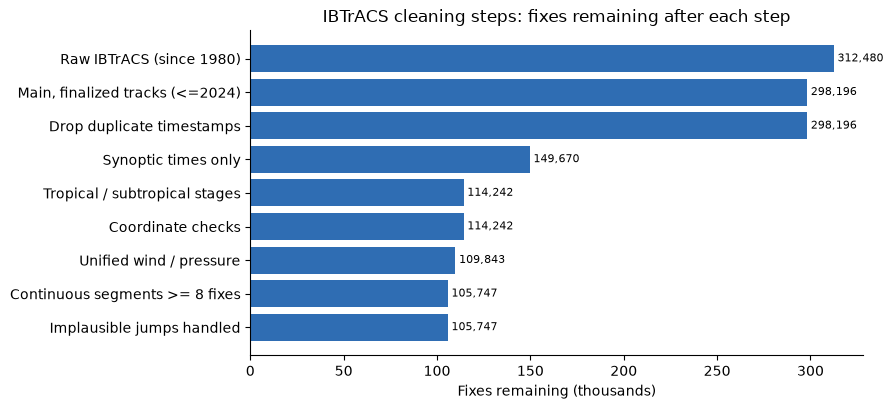

In [18]:
# Figure 1: how many fixes survive each cleaning step
fig, ax = plt.subplots(figsize=(9, 4.2))
labels = [s.split(". ", 1)[1] for s in log_df["step"]]
ax.barh(labels[::-1], log_df["rows"][::-1] / 1000, color="#2f6db3")
for i, v in enumerate(log_df["rows"][::-1]):
    ax.text(v / 1000 + 2, i, f"{v:,}", va="center", fontsize=8)
ax.set_xlabel("Fixes remaining (thousands)")
ax.set_title("IBTrACS cleaning steps: fixes remaining after each step")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig01_cleaning_funnel.png", dpi=200)
plt.show()

## Summary

* Started from 312,480 raw IBTrACS rows (1980 onward) and kept only finalized main best tracks through 2024.
* Removed interpolated and off-hour rows so every fix is on the 6-hourly synoptic grid.
* Kept tropical and subtropical stages, built a single 1-minute wind column (with 10-minute winds converted)
  and a single pressure column, and filled only short gaps.
* Split storms into continuous 6-hour segments of at least 42 hours (105,747 fixes, 4,162 segments, 4,021 storms remain).
* Checked for physically implausible jumps (> 120 km/h); none were found, and the fastest step was about 112 km/h.
* All Atlantic fixes match HURDAT2 exactly (0 km difference), confirming the cleaning did not corrupt the tracks.
* Seasons are split into train (1980–2016), validation (2017–2019) and test (2020–2024).

**In production**, the same steps would run on each new advisory: the NHC/JTWC operational fixes (ATCF / TCVitals)
arrive every 6 hours on the synoptic grid, so the pipeline would append the new fix, apply the same wind-unit
conversion and checks, and pass the latest four fixes to the model.

### References
Gahtan, J., Knapp, K. R., Schreck, C. J., Diamond, H. J., Kossin, J. P., & Kruk, M. C. (2024). *International Best Track Archive for Climate Stewardship (IBTrACS) Project, Version 4r01*. NOAA National Centers for Environmental Information. https://doi.org/10.25921/82ty-9e16

Harper, B. A., Kepert, J. D., & Ginger, J. D. (2010). *Guidelines for converting between various wind averaging periods in tropical cyclone conditions* (WMO/TD-No. 1555). World Meteorological Organization.

Knapp, K. R., Kruk, M. C., Levinson, D. H., Diamond, H. J., & Neumann, C. J. (2010). The International Best Track Archive for Climate Stewardship (IBTrACS). *Bulletin of the American Meteorological Society, 91*(3), 363–376.

Landsea, C. W., & Franklin, J. L. (2013). Atlantic hurricane database uncertainty and presentation of a new database format. *Monthly Weather Review, 141*(10), 3576–3592.

*AI-tool disclosure: Claude (Anthropic) helped draft this notebook's code and explanations. The author reviewed each step, ran the notebook, and checked the outputs.*